# Lab 01 – Dự đoán khối lượng chim cánh cụt

**Mã nhóm** [Điền mã nhóm]  
**Thành viên** [Điền họ tên và MSSV của 4 thành viên]

Chạy các cell theo thứ tự. M1–M4 là bốn vị trí để mỗi thành viên tự chọn một thuật toán hồi quy tuyến tính. Điền các mục **TODO** khi hoàn thiện bài nhóm.

## 1. Mô tả bài toán

Mục tiêu đề xuất là dự đoán khối lượng cơ thể, `body_mass_g` (g). Bộ biến mẫu gồm chiều dài cánh bơi, chiều dài và độ sâu mỏ, loài và giới tính. Sau EDA, nhóm chốt đầu vào dùng chung cho bốn thuật toán.

**TODO** Viết động cơ chọn bài toán, câu hỏi nghiên cứu và giải thích lựa chọn bộ biến đầu vào.

## 2. Nạp và khám phá dữ liệu

Notebook đọc CSV trong thư mục `data/`. Nguồn dữ liệu là bản `penguins` đã đơn giản hóa. [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/)

In [1]:
from pathlib import Path
import sys

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd()
if not (project_root / "data" / "penguins.csv").is_file():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from source.modeling import CATEGORICAL, FEATURES, TARGET, load_penguins, regression_metrics, split_penguins
from source.models import m1, m2, m3, m4

LABELS = {
    "flipper_length_mm": "Chiều dài cánh bơi (mm)",
    "bill_length_mm": "Chiều dài mỏ (mm)",
    "bill_depth_mm": "Độ sâu mỏ (mm)",
    "year": "Năm quan sát",
    "species": "Loài",
    "island": "Đảo",
    "sex": "Giới tính",
    "body_mass_g": "Khối lượng cơ thể (g)",
}

penguins = load_penguins()
print(f"Dữ liệu gốc: {len(penguins)} dòng, {penguins.shape[1]} cột")

Dữ liệu gốc: 344 dòng, 8 cột


### Chia tập và xem dữ liệu huấn luyện

Loại các dòng thiếu giá trị đích vì chúng không có nhãn để huấn luyện hoặc đánh giá. Dùng một lần chia 80/20 với seed 42 cho toàn bộ các mô hình. Pipeline học cách điền thiếu, chuẩn hóa và mã hóa trên tập huấn luyện.

Các bảng và biểu đồ bên dưới dùng `train_data` để đề xuất bộ biến. Tập test được dành cho lượt đánh giá sau khi chốt cấu hình.

In [2]:
train_data, test_data = split_penguins(penguins)
y_train = train_data[TARGET]
y_test = test_data[TARGET]

print(f"Huấn luyện: {len(train_data)} dòng | Kiểm tra: {len(test_data)} dòng")

print(f"Dòng thiếu biến đích trong CSV: {penguins[TARGET].isna().sum()}")
print(f"Dòng trùng toàn bộ cột trong tập train: {train_data.duplicated().sum()}")
display(train_data.head())
display(pd.DataFrame({
    "Kiểu dữ liệu": train_data.dtypes.astype(str),
    "Số giá trị thiếu": train_data.isna().sum(),
    "Tỷ lệ thiếu (%)": train_data.isna().mean().mul(100).round(2),
}))

Huấn luyện: 273 dòng | Kiểm tra: 69 dòng
Dòng thiếu biến đích trong CSV: 2
Dòng trùng toàn bộ cột trong tập train: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
115,Adelie,Biscoe,42.7,18.3,196.0,4075.0,male,2009
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
138,Adelie,Dream,37.0,16.5,185.0,3400.0,female,2009
334,Chinstrap,Dream,50.2,18.8,202.0,3800.0,male,2009
306,Chinstrap,Dream,40.9,16.6,187.0,3200.0,female,2008


,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%)
species,object,0,0.00
island,object,0,0.00
bill_length_mm,float64,0,0.00
bill_depth_mm,float64,0,0.00
flipper_length_mm,float64,0,0.00
body_mass_g,float64,0,0.00
sex,object,5,1.83
year,int64,0,0.00


,count,mean,std,min,25%,50%,75%,max
body_mass_g,273.0,4207.88,814.24,2700.0,3550.0,4000.0,4850.0,6300.0
flipper_length_mm,273.0,201.10,14.20,172.0,190.0,197.0,214.0,231.0
bill_length_mm,273.0,43.98,5.54,32.1,39.2,44.5,48.6,59.6
bill_depth_mm,273.0,17.11,1.96,13.1,15.5,17.3,18.6,21.5


,body_mass_g,flipper_length_mm,bill_length_mm,bill_depth_mm
body_mass_g,1.000,0.869,0.580,-0.475
flipper_length_mm,0.869,1.000,0.651,-0.573
bill_length_mm,0.580,0.651,1.000,-0.226
bill_depth_mm,-0.475,-0.573,-0.226,1.000


,flipper_length_mm,bill_length_mm,bill_depth_mm
Loài,,,
Adelie,0.419,0.516,0.590
Chinstrap,0.631,0.498,0.600
Gentoo,0.693,0.657,0.714


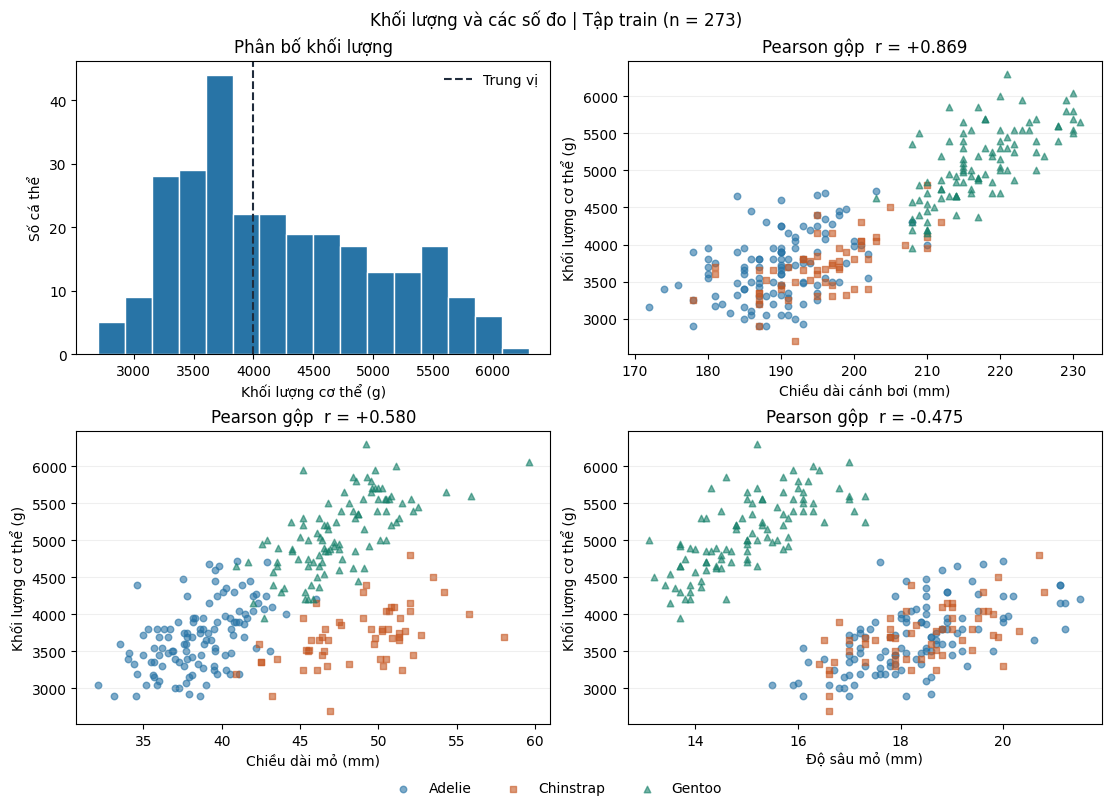

In [3]:
measurement_features = ["flipper_length_mm", "bill_length_mm", "bill_depth_mm"]
numeric_columns = [TARGET, *measurement_features]
pearson = train_data[numeric_columns].corr()

species_groups = dict(iter(train_data.groupby("species")))
species_colors = dict(zip(species_groups, ["#2874A6", "#C65721", "#16806A"]))
species_markers = dict(zip(species_groups, ["o", "s", "^"]))

display(train_data[numeric_columns].describe().T.round(2))
display(pearson.round(3))
pearson_by_species = pd.DataFrame({
    species: group[measurement_features].corrwith(group[TARGET])
    for species, group in species_groups.items()
}).T
display(pearson_by_species.rename_axis("Loài").round(3))

numeric_figure, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
hist_ax = axes.flat[0]
hist_ax.hist(y_train, bins=16, color="#2874A6", edgecolor="white")
hist_ax.axvline(y_train.median(), color="#202C3C", linestyle="--", label="Trung vị")
hist_ax.set(xlabel=LABELS[TARGET], ylabel="Số cá thể", title="Phân bố khối lượng")
hist_ax.legend(frameon=False)

for ax, feature in zip(axes.flat[1:], measurement_features):
    for species, group in species_groups.items():
        ax.scatter(
            group[feature], group[TARGET], label=species, color=species_colors[species],
            marker=species_markers[species], alpha=0.60, s=22,
        )
    ax.set(
        xlabel=LABELS[feature], ylabel=LABELS[TARGET],
        title=f"Pearson gộp  r = {pearson.loc[feature, TARGET]:+.3f}",
    )
    ax.grid(axis="y", alpha=0.20)

handles, labels = axes.flat[1].get_legend_handles_labels()
numeric_figure.legend(handles, labels, loc="outside lower center", ncols=3, frameon=False)
numeric_figure.suptitle(f"Khối lượng và các số đo | Tập train (n = {len(train_data)})")
plt.show()

,n,median_g
species,,
Adelie,116,3700.0
Chinstrap,57,3700.0
Gentoo,100,5050.0


n  median_g
species   sex                 
Adelie    female  59    3350.0
          male    54    3962.5
          NaN      3    3700.0
Chinstrap female  31    3525.0
          male    26    3950.0
Gentoo    female  46    4700.0
          male    52    5500.0
          NaN      2    4762.5

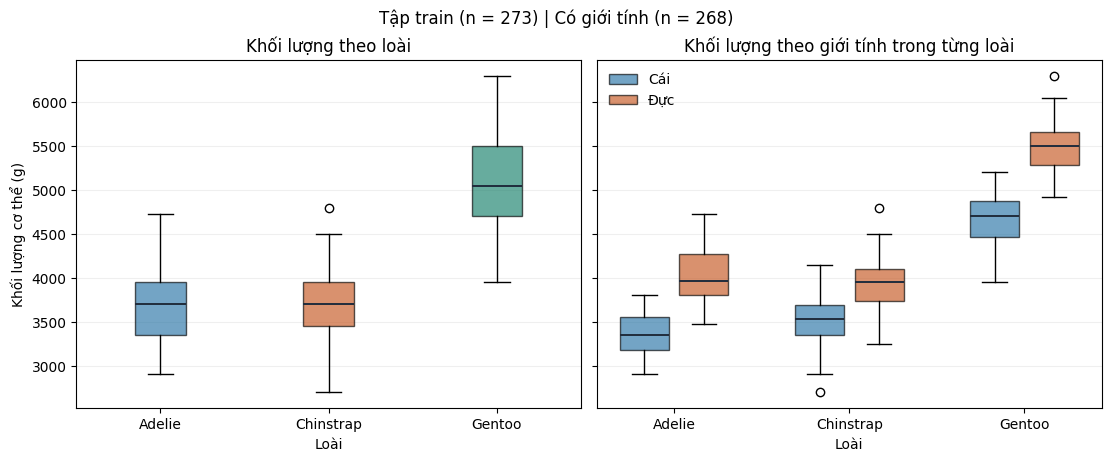

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,34,0,100
Dream,46,57,0
Torgersen,36,0,0


,n,median_g
year,,
2007,87,3900.0
2008,94,4275.0
2009,92,3987.5


In [4]:
species_summary = train_data.groupby("species")[TARGET].agg(n="size", median_g="median")
sex_summary = train_data.groupby(["species", "sex"], dropna=False)[TARGET].agg(
    n="size", median_g="median",
)
display(species_summary)
display(sex_summary)

category_figure, (species_ax, sex_ax) = plt.subplots(
    1, 2, figsize=(11, 4.5), sharey=True, layout="constrained",
)
species_box = species_ax.boxplot(
    [group[TARGET] for group in species_groups.values()],
    tick_labels=list(species_groups), patch_artist=True,
    medianprops={"color": "#202C3C", "linewidth": 1.4},
)
for box, color in zip(species_box["boxes"], species_colors.values()):
    box.set_facecolor(color)
    box.set_alpha(0.65)
species_ax.set(xlabel=LABELS["species"], ylabel=LABELS[TARGET], title="Khối lượng theo loài")

positions = np.arange(1, len(species_groups) + 1)
sex_legend = []
for sex, label, color, offset in [
    ("female", "Cái", "#2874A6", -0.17),
    ("male", "Đực", "#C65721", 0.17),
]:
    boxes = sex_ax.boxplot(
        [group.loc[group["sex"] == sex, TARGET] for group in species_groups.values()],
        positions=positions + offset, widths=0.28, patch_artist=True,
        manage_ticks=False, medianprops={"color": "#202C3C", "linewidth": 1.4},
    )
    for box in boxes["boxes"]:
        box.set_facecolor(color)
        box.set_alpha(0.65)
    sex_legend.append((boxes["boxes"][0], label))

sex_ax.set_xticks(positions, list(species_groups))
sex_ax.set(xlabel=LABELS["species"], title="Khối lượng theo giới tính trong từng loài")
sex_ax.legend(*zip(*sex_legend), frameon=False)
for ax in (species_ax, sex_ax):
    ax.grid(axis="y", alpha=0.20)

known_sex_count = int(train_data["sex"].notna().sum())
category_figure.suptitle(f"Tập train (n = {len(train_data)}) | Có giới tính (n = {known_sex_count})")
plt.show()

display(pd.crosstab(train_data["island"], train_data["species"]))
display(train_data.groupby("year")[TARGET].agg(n="size", median_g="median"))

### Nhận xét và đề xuất bộ biến

Chiều dài cánh bơi có tương quan Pearson gộp cao nhất trong ba số đo. Độ sâu mỏ đổi dấu tương quan khi tách theo loài, nên nhóm xem cả hai cách tính khi đánh giá vai trò của biến này. Trung vị khối lượng khác theo loài và theo giới tính trong từng loài.

Đề xuất giữ ba số đo, loài và giới tính làm bộ đầu vào ban đầu. Đảo và năm được ghi trong dữ liệu khảo sát. Báo cáo EDA tóm tắt lý do cho từng biến và các điều kiện cần xác nhận trước khi chốt. [Kết quả EDA và biểu đồ](../report/eda-week1.md)

## 3. Thiết kế và huấn luyện mô hình

Điền estimator do bạn chọn vào `ESTIMATOR` trong tệp phụ trách. Notebook đánh dấu vị trí còn trống là **Chưa sẵn sàng**. OLS được huấn luyện cùng các mô hình đã khai báo để làm baseline.

Pipeline chung điền trung vị và chuẩn hóa cho biến số. Khi dùng M2, bước chuẩn hóa được thay bằng phép biến đổi cơ sở spline. Với biến phân loại, pipeline điền mức phổ biến nhất và mã hóa one-hot với một mức tham chiếu.

**TODO** Mỗi người chọn một thuật toán hồi quy tuyến tính riêng, ghi lý do chọn và các siêu tham số đã dùng. Sau khi sửa tệp, khởi động lại kernel và chạy toàn bộ notebook. [M1](models/m1.py) · [M2](models/m2.py) · [M3](models/m3.py) · [M4](models/m4.py)

In [ ]:
from source.models import ols

model_modules = (ols, m1, m2, m3, m4)
models = {}
model_info = []
for module in model_modules:
    ready = module is ols or module.ESTIMATOR is not None
    estimator = "—"
    if ready:
        model = module.build_model().fit(train_data[FEATURES], y_train)
        models[module.NAME] = model
        estimator = type(model.named_steps["regression"]).__name__
    model_info.append({
        "Mô hình": module.NAME,
        "Estimator đang chạy": estimator,
        "Trạng thái": "Sẵn sàng" if ready else "Chưa sẵn sàng",
    })
display(pd.DataFrame(model_info).set_index("Mô hình"))

## 4. Đánh giá và diễn giải

So sánh MAE, MSE, RMSE và R² trên cùng tập kiểm tra. MAE và RMSE tính bằng gram, MSE bằng g², R² không có đơn vị. Chọn mô hình ở danh sách bên dưới để xem hệ số và phần dư (thực tế trừ dự đoán).

Với OLS, hệ số của số đo tính theo gram trên một độ lệch chuẩn train. M2 ước lượng hệ số của các hàm cơ sở. M3 thể hiện ảnh hưởng qua ba đường spline định tâm. [Kiểm định OLS, CV và so sánh OLS–M3](../report/section-3-3-evaluation.md)

In [ ]:
from sklearn.metrics import mean_squared_error

predictions = {}
scores = []
for name, model in models.items():
    y_pred = model.predict(test_data[FEATURES])
    predictions[name] = y_pred
    scores.append({
        "Mô hình": name,
        **regression_metrics(y_test, y_pred),
        "MSE (g²)": mean_squared_error(y_test, y_pred),
    })

results = pd.DataFrame(scores).set_index("Mô hình")[["MAE (g)", "MSE (g²)", "RMSE (g)", "R²"]]
display(results.round({"MAE (g)": 1, "MSE (g²)": 1, "RMSE (g)": 1, "R²": 3}))

In [ ]:
def show_diagnostics(model_name):
    model = models[model_name]
    preprocessor = model.named_steps["preprocess"]
    regression = model.named_steps["regression"]
    coefficient_model = getattr(regression, "estimator_", regression)

    if hasattr(coefficient_model, "coef_") and hasattr(coefficient_model, "intercept_"):
        intercept = np.asarray(coefficient_model.intercept_).item()
        print(f"{model_name} | Hệ số chặn: {intercept:.2f} g")
        display(pd.Series(
            np.ravel(coefficient_model.coef_),
            index=preprocessor.get_feature_names_out(),
            name="Hệ số",
        ).round(3).to_frame())
    else:
        print(f"{model_name} | Xem phần dư bên dưới và tra tài liệu estimator để trích hệ số.")

    categorical_features = [
        feature for feature in FEATURES if feature in CATEGORICAL
    ]
    if categorical_features:
        encoder = preprocessor.named_transformers_["categorical"].named_steps["encoder"]
        for feature, levels, reference_index in zip(
            categorical_features, encoder.categories_, encoder.drop_idx_
        ):
            print(f"Mức tham chiếu của {feature}: {levels[reference_index]}")

    y_pred = predictions[model_name]
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    ax.scatter(y_pred, y_test - y_pred, alpha=0.65, color="#246b83")
    ax.axhline(0, color="#475569", linestyle="--")
    ax.set(xlabel="Dự đoán (g)", ylabel="Thực tế − dự đoán (g)", title="Phần dư trên tập kiểm tra")
    plt.show()
    plt.close(fig)

diagnostics = widgets.interactive(
    show_diagnostics, model_name=widgets.Dropdown(options=list(models), description="Mô hình"),
)
display(diagnostics)

## 5. Giao diện dự đoán

Chọn mô hình, chỉnh đầu vào rồi bấm **Dự đoán** để xem khối lượng theo gram. Bật chế độ so sánh để xem mọi mô hình sẵn sàng. Khi hai đường OLS và M3 cùng xuất hiện, biểu đồ số đo có thêm ô chênh lệch M3 − OLS. Mỗi đường giữ cố định các đầu vào còn lại. Các điểm nền là quan sát train với nhiều tổ hợp đầu vào.

Chọn OLS để xem thêm CI 95% cho khối lượng trung bình và PI 95% cho một cá thể theo giả định OLS cổ điển. [Kịch bản demo và cách đọc kết quả](../report/section-3-4-application.md)

In [ ]:
from source.prediction_app import PredictionApp

prediction_app = PredictionApp(models, train_data, LABELS)
display(prediction_app.panel)
prediction_app.predict_button.click()

## 6. Kết luận và tài liệu tham khảo

**TODO** Tóm tắt câu trả lời cho mục tiêu của nhóm. Dẫn số liệu từ bảng đánh giá, biểu đồ hoặc hệ số cho từng nhận xét chính. Ghi các giới hạn quan sát được và đưa phần trình bày đầy đủ vào báo cáo.

Horst, A. M., Hill, A. P., & Gorman, K. B. (2020). *palmerpenguins: Palmer Archipelago (Antarctica) penguin data*. [DOI 10.5281/zenodo.3960218](https://doi.org/10.5281/zenodo.3960218)